# 02 · EDA: Claims
**BEV vs. ICE Motor Property Insurance**

**Purpose:** compare BEV, Hybrid and ICE on the three pillars of the pure premium:
1. **Frequency**: claims per vehicle-year of exposure.
2. **Severity**: own-damage (repair) cost per claim.
3. **Total-loss incidence**: write-off rate and its cost impact.

**Inputs:** `data/raw/claims_raw.csv`, inner-joined on `Policy_ID` to `data/raw/policies_raw.csv` for powertrain and exposure. The harmonisation below is for EDA only; the definitive cleaning belongs in `src/01_etl_merge_and_clean.R`.

**Field mapping:** the extract has no single `Claim_Amount` or `Total_Loss` column. We use:
- `Own_Damage_Amount`: repair cost of the insured vehicle. This is the **severity measure**, because powertrain acts directly on it.
- `TP_Damage_Amount`: third-party property damage. It depends mainly on the *other* vehicle, so it is reported only as a side check.
- `Is_Total_Loss`: write-off flag (0/1).

## 1. Setup & Data Ingestion

In [1]:
# suppressWarnings hides "package built under R 4.5.x" notices
suppressWarnings(suppressPackageStartupMessages({
  library(tidyverse)
  library(scales)
  library(lubridate)
}))

options(repr.plot.width = 10, repr.plot.height = 5, repr.plot.res = 110,
        dplyr.summarise.inform = FALSE)
theme_set(theme_minimal(base_size = 12))

pt_colours <- c(BEV = "#1b9e77", Hybrid = "#7570b3", ICE = "#d95f02")

# Works whether the notebook runs from notebooks/ or from the repository root
find_raw <- function(file) {
  path <- file.path(c("../data/raw", "data/raw"), file) |> keep(file.exists) |> first()
  if (is.na(path)) stop("Cannot find ", file)
  path
}

# Quantile summary of a numeric variable by powertrain
severity_summary <- function(data, var) {
  data |>
    filter(!is.na({{ var }})) |>
    group_by(Powertrain) |>
    summarise(claims = n(),
              mean   = mean({{ var }}),
              median = median({{ var }}),
              p25    = quantile({{ var }}, 0.25),
              p75    = quantile({{ var }}, 0.75),
              p95    = quantile({{ var }}, 0.95),
              p99    = quantile({{ var }}, 0.99))
}

### 1.1 Load claims and inspect structure
All columns are read as text first, because the amounts contain currency symbols and thousands separators.

In [2]:
claims_raw <- read_csv(find_raw("claims_raw.csv"), col_types = cols(.default = col_character()))

cat("Rows:", nrow(claims_raw), "| Columns:", ncol(claims_raw), "\n\n")
glimpse(claims_raw)

Rows: 6664 | Columns: 7 



Rows: 6,664
Columns: 7
$ Claim_ID          <chr> "C849378", "C733412", "C936030", "C928394", "C826146…
$ Policy_ID         <chr> "P2243106", "P2965488", "P2476508", "P2465223", "P24…
$ Accident_Date     <chr> "2024-07-05", "2025-02-25", "2025-05-24", "2024-09-1…
$ Claim_Type        <chr> "Collision_With_TP", "Collision_No_TP", "Collision_N…
$ Own_Damage_Amount <chr> "0.0", "5576.3", "-3450.51", "1313.01", "1410.41", "…
$ TP_Damage_Amount  <chr> "3967.45", NA, NA, NA, NA, NA, NA, NA, "14612.99", "…
$ Is_Total_Loss     <chr> "0", "0", "0", "0", "0", "0", "0", "0", "0", "0", "0…


In [3]:
claims_raw |>
  summarise(across(everything(), ~ sum(is.na(.x)))) |>
  pivot_longer(everything(), names_to = "column", values_to = "n_missing") |>
  mutate(pct_missing = percent(n_missing / nrow(claims_raw), accuracy = 0.1))

column,n_missing,pct_missing
<chr>,<int>,<chr>
Claim_ID,0,0.0%
Policy_ID,0,0.0%
Accident_Date,0,0.0%
Claim_Type,122,1.8%
Own_Damage_Amount,0,0.0%
TP_Damage_Amount,4301,64.5%
Is_Total_Loss,0,0.0%


### 1.2 Field audit: identifiers, dates, claim types, amounts
`TP_Damage_Amount` is missing for most claims. That is **structural**: there is no third party in single-vehicle, theft or weather claims.

In [4]:
od_raw <- parse_number(claims_raw$Own_Damage_Amount)

tribble(
  ~check,                                             ~value,
  "Exact duplicate rows",                             sum(duplicated(claims_raw)),
  "Duplicate Claim_ID (after removing exact dups)",   sum(duplicated(distinct(claims_raw)$Claim_ID)),
  "Accident_Date unparseable",                        sum(is.na(ymd(claims_raw$Accident_Date, quiet = TRUE))),
  "Claim_Type missing",                               sum(is.na(claims_raw$Claim_Type)),
  "Claim_Type distinct raw labels",                   n_distinct(claims_raw$Claim_Type, na.rm = TRUE),
  "Amounts stored as text (currency / commas)",       sum(str_detect(claims_raw$Own_Damage_Amount, "[^0-9.-]")),
  "Own_Damage_Amount < 0",                            sum(od_raw < 0),
  "Own_Damage_Amount = 0",                            sum(od_raw == 0),
  "Is_Total_Loss values other than 0/1",              sum(!claims_raw$Is_Total_Loss %in% c("0", "1"))
)

cat("\nAccident dates:", format(range(ymd(claims_raw$Accident_Date))), "\n")
count(claims_raw, Claim_Type, sort = TRUE)

check,value
<chr>,<int>
Exact duplicate rows,60
Duplicate Claim_ID (after removing exact dups),0
Accident_Date unparseable,0
Claim_Type missing,122
Claim_Type distinct raw labels,14
Amounts stored as text (currency / commas),282
Own_Damage_Amount < 0,36
Own_Damage_Amount = 0,356
Is_Total_Loss values other than 0/1,0



Accident dates: 2024-01-03 2025-12-23 


Claim_Type,n
<chr>,<int>
Collision_With_TP,2149
Single_Vehicle_Accident,1289
Collision_No_TP,1280
Natural_Hazard,705
Malicious_Damage,445
Theft,239
NA,122
Accident,86
Self Accident,82


### 1.3 Exposure base from policies
This mirrors the policy harmonisation in notebook 01 §1.4: de-duplicate, parse both date formats, compute exposure in years, and rescale vehicle values recorded in ₪ thousands.

In [5]:
policies <- read_csv(find_raw("policies_raw.csv"), col_types = cols(.default = col_character())) |>
  distinct() |>
  mutate(
    start_date    = as_date(parse_date_time(Start_Date, orders = c("Ymd", "dmY"))),
    end_date      = ymd(End_Date),
    exposure      = as.numeric(end_date - start_date + 1) / 365.25,
    exposure      = if_else(exposure > 0 & exposure <= 1.01, exposure, NA_real_),
    Powertrain    = factor(str_trim(Powertrain), levels = c("BEV", "Hybrid", "ICE")),
    Vehicle_Value = as.numeric(Vehicle_Value),
    Vehicle_Value = case_when(Vehicle_Value <= 0   ~ NA_real_,
                              Vehicle_Value < 1000 ~ Vehicle_Value * 1000,
                              .default = Vehicle_Value)
  ) |>
  slice_max(exposure, n = 1, with_ties = FALSE, by = Policy_ID) |>
  select(Policy_ID, Powertrain, start_date, end_date, exposure, Vehicle_Value)

cat("Policies:", nrow(policies), "| with valid exposure:", sum(!is.na(policies$exposure)), "\n")

Policies: 38412 | with valid exposure: 38328 


### 1.4 Claims working copy
- Drop exact duplicates, parse the amounts, and harmonise the 14 claim-type labels into 8 categories.
- Inner-join to policies, which drops orphan claims, and flag:
  - **in_period**: the accident falls inside the policy's exposure window;
  - **cat_event**: a weather catastrophe on 2025-01-19 (see §2.3);
  - **valid_amount**: own damage > 0 and ≤ 2 × vehicle value.

In [6]:
cat_date <- as_date("2025-01-19")

claims <- claims_raw |>
  distinct() |>
  mutate(
    accident_date = ymd(Accident_Date),
    own_damage    = parse_number(Own_Damage_Amount),
    tp_damage     = parse_number(TP_Damage_Amount),
    total_loss    = Is_Total_Loss == "1",
    type_code     = str_replace_all(str_to_lower(str_trim(Claim_Type)), "[ _]+", "_"),
    claim_type    = case_when(
      type_code %in% c("natural_hazard", "weather", "flood")                    ~ "Natural hazard",
      type_code %in% c("single_vehicle_accident", "self_accident", "single_vehicle") ~ "Single vehicle",
      type_code == "collision_with_tp"                                          ~ "Collision with TP",
      type_code == "collision_no_tp"                                            ~ "Collision no TP",
      type_code == "malicious_damage"                                           ~ "Malicious damage",
      type_code == "theft"                                                      ~ "Theft",
      type_code == "fire"                                                       ~ "Fire",
      .default                                                                  = "Unspecified"
    )
  ) |>
  select(-type_code)

n_orphans <- sum(!claims$Policy_ID %in% policies$Policy_ID)

claims <- claims |>
  inner_join(policies, by = "Policy_ID") |>
  mutate(in_period    = !is.na(exposure) & between(accident_date, start_date, end_date),
         cat_event    = accident_date == cat_date,
         damage_ratio = own_damage / Vehicle_Value,
         valid_amount = own_damage > 0 & (is.na(damage_ratio) | damage_ratio <= 2))

cat("Claims after de-dup:", nrow(distinct(claims_raw)), "| orphans dropped:", n_orphans,
    "| joined:", nrow(claims), "| in period:", sum(claims$in_period), "\n")

# Analysis base: claims that fall within a valid exposure window
claims_ip <- filter(claims, in_period)

Claims after de-dup: 6604 | orphans dropped: 72 | joined: 6532 | in period: 6445 


## 2. Claim Volume & Frequency
### 2.1 Claims per policy

In [7]:
claim_counts <- policies |>
  filter(!is.na(exposure)) |>
  left_join(count(claims_ip, Policy_ID, name = "n_claims"), by = "Policy_ID") |>
  mutate(n_claims = replace_na(n_claims, 0L))

claim_counts |>
  mutate(claims_band = case_when(n_claims == 0 ~ "0", n_claims == 1 ~ "1", .default = "2+")) |>
  count(Powertrain, claims_band) |>
  group_by(Powertrain) |>
  mutate(share = percent(n / sum(n), accuracy = 0.1)) |>
  select(-n) |>
  pivot_wider(names_from = claims_band, values_from = share)

Powertrain,0,1,2+
<fct>,<chr>,<chr>,<chr>
BEV,84.7%,13.6%,1.7%
Hybrid,84.9%,13.1%,1.9%
ICE,85.4%,13.0%,1.7%


### 2.2 Claim frequency per vehicle-year
Frequency = claims / earned exposure, with an approximate 95% Poisson confidence interval. The 2025-01-19 CAT event is shown separately, because catastrophe losses are normally priced with a separate loading.

In [8]:
frequency <- claim_counts |>
  group_by(Powertrain) |>
  summarise(exposure_years = sum(exposure)) |>
  left_join(claims_ip |>
              group_by(Powertrain) |>
              summarise(claims_all = n(), claims_ex_cat = sum(!cat_event)),
            by = "Powertrain") |>
  mutate(freq_all    = claims_all / exposure_years,
         freq_ex_cat = claims_ex_cat / exposure_years,
         ci_low      = (claims_ex_cat - 1.96 * sqrt(claims_ex_cat)) / exposure_years,
         ci_high     = (claims_ex_cat + 1.96 * sqrt(claims_ex_cat)) / exposure_years)

frequency |>
  mutate(exposure_years = comma(exposure_years, accuracy = 1),
         across(c(freq_all, freq_ex_cat, ci_low, ci_high), ~ percent(.x, accuracy = 0.1)))

Powertrain,exposure_years,claims_all,claims_ex_cat,freq_all,freq_ex_cat,ci_low,ci_high
<fct>,<chr>,<int>,<int>,<chr>,<chr>,<chr>,<chr>
BEV,"4,121",759,696,18.4%,16.9%,15.6%,18.1%
Hybrid,"7,754",1412,1287,18.2%,16.6%,15.7%,17.5%
ICE,"24,473",4274,3907,17.5%,16.0%,15.5%,16.5%


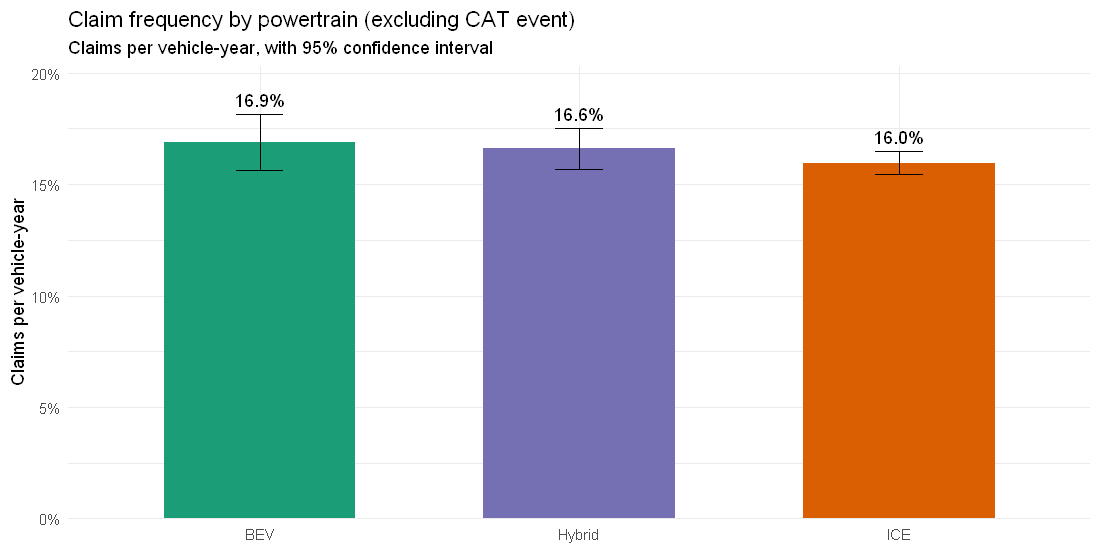

In [9]:
ggplot(frequency, aes(Powertrain, freq_ex_cat, fill = Powertrain)) +
  geom_col(width = 0.6) +
  geom_errorbar(aes(ymin = ci_low, ymax = ci_high), width = 0.15) +
  geom_text(aes(y = ci_high, label = percent(freq_ex_cat, accuracy = 0.1)), vjust = -0.6) +
  scale_fill_manual(values = pt_colours, guide = "none") +
  scale_y_continuous(labels = percent, expand = expansion(mult = c(0, 0.12))) +
  labs(title = "Claim frequency by powertrain (excluding CAT event)",
       subtitle = "Claims per vehicle-year, with 95% confidence interval",
       x = NULL, y = "Claims per vehicle-year")

### 2.3 Monthly incidence trend
Raw monthly claim counts mostly reflect how much exposure is in force, which ramps up through 2024 and runs off through 2025. We therefore plot the **annualised frequency**: monthly claims divided by the exposure earned in that month.

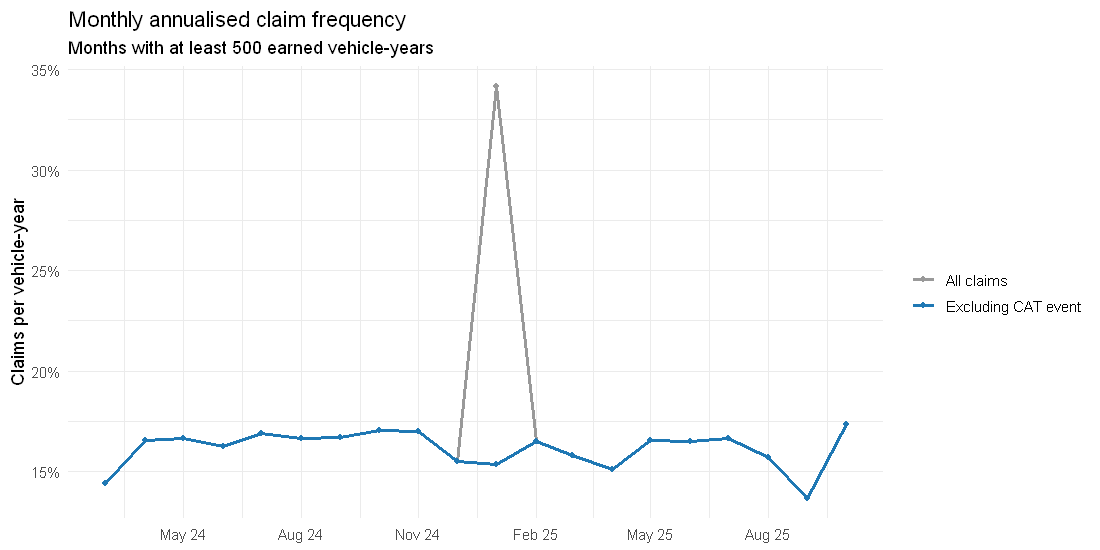

In [10]:
months <- tibble(month = seq(floor_date(min(policies$start_date, na.rm = TRUE), "month"),
                             floor_date(max(policies$end_date,   na.rm = TRUE), "month"),
                             by = "month"))

earned <- policies |>
  filter(!is.na(exposure)) |>
  select(start_date, end_date) |>
  cross_join(months) |>
  mutate(days = as.numeric(pmin(end_date, ceiling_date(month, "month") - 1) -
                           pmax(start_date, month) + 1)) |>
  filter(days > 0) |>
  summarise(exposure_years = sum(days) / 365.25, .by = month)

monthly <- claims_ip |>
  mutate(month = floor_date(accident_date, "month")) |>
  summarise(`All claims` = n(), `Excluding CAT event` = sum(!cat_event), .by = month) |>
  inner_join(earned, by = "month") |>
  filter(exposure_years >= 500) |>              # drop thin run-in / run-off months
  pivot_longer(c(`All claims`, `Excluding CAT event`), names_to = "series", values_to = "claims") |>
  mutate(frequency = claims / exposure_years)

ggplot(monthly, aes(month, frequency, colour = series)) +
  geom_line(linewidth = 1) +
  geom_point(size = 1.5) +
  scale_colour_manual(values = c("grey60", "#1f78b4")) +
  scale_y_continuous(labels = percent) +
  scale_x_date(date_breaks = "3 months",
               labels = \(x) paste(month.abb[month(x)], format(x, "%y"))) +   # locale-independent
  labs(title = "Monthly annualised claim frequency",
       subtitle = "Months with at least 500 earned vehicle-years",
       x = NULL, y = "Claims per vehicle-year", colour = NULL)

In [11]:
# The January 2025 spike: claim types on the CAT date
claims_ip |>
  filter(cat_event) |>
  count(claim_type, sort = TRUE) |>
  mutate(share = percent(n / sum(n), accuracy = 0.1))

claim_type,n,share
<chr>,<int>,<chr>
Natural hazard,529,95.3%
Unspecified,9,1.6%
Collision no TP,7,1.3%
Collision with TP,6,1.1%
Malicious damage,2,0.4%
Single vehicle,2,0.4%


### 2.4 Claim-type mix (excluding CAT event)

In [12]:
claims_ip |>
  filter(!cat_event) |>
  count(Powertrain, claim_type) |>
  group_by(Powertrain) |>
  mutate(share = percent(n / sum(n), accuracy = 0.1)) |>
  select(-n) |>
  pivot_wider(names_from = Powertrain, values_from = share, values_fill = "0.0%") |>
  arrange(claim_type)

claim_type,BEV,Hybrid,ICE
<chr>,<chr>,<chr>,<chr>
Collision no TP,20.7%,21.1%,20.7%
Collision with TP,36.5%,33.6%,35.6%
Fire,0.6%,0.7%,0.7%
Malicious damage,7.6%,7.5%,7.3%
Natural hazard,5.0%,4.2%,5.4%
Single vehicle,26.1%,23.2%,23.5%
Theft,0.7%,6.6%,3.5%
Unspecified,2.7%,3.1%,3.4%


## 3. Claim Severity (Own-Damage Cost per Claim)
Base: attritional claims (CAT event excluded) with a valid own-damage amount.

In [13]:
sev <- claims_ip |> filter(!cat_event, valid_amount)

severity_summary(sev, own_damage) |>
  mutate(mean_to_median = number(mean / median, accuracy = 0.01),
         across(mean:p99, ~ comma(.x, accuracy = 1, prefix = "₪")))

Powertrain,claims,mean,median,p25,p75,p95,p99,mean_to_median
<fct>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
BEV,650,"₪21,933","₪9,551","₪4,318","₪24,365","₪91,109","₪157,009",2.30
Hybrid,1209,"₪17,928","₪7,017","₪3,380","₪15,406","₪90,654","₪142,352",2.55
ICE,3656,"₪11,058","₪4,726","₪2,152","₪11,056","₪47,276","₪100,583",2.34


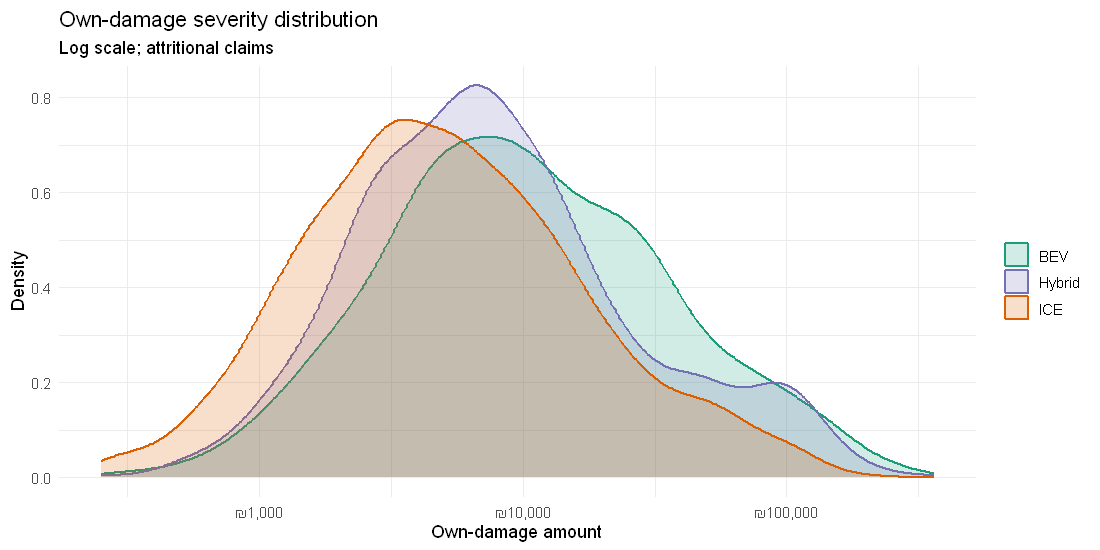

In [14]:
ggplot(sev, aes(own_damage, fill = Powertrain, colour = Powertrain)) +
  geom_density(alpha = 0.2, linewidth = 0.8) +
  scale_x_log10(labels = label_comma(prefix = "₪")) +
  scale_fill_manual(values = pt_colours) +
  scale_colour_manual(values = pt_colours) +
  labs(title = "Own-damage severity distribution",
       subtitle = "Log scale; attritional claims",
       x = "Own-damage amount", y = "Density", fill = NULL, colour = NULL)

### 3.1 Systematic shift or heavy tail?
The **quantile ratio** BEV ÷ ICE across the distribution answers this directly. A flat line means a uniform shift (every claim costs proportionally more), while a line that rises towards the right means the gap is driven by large claims.

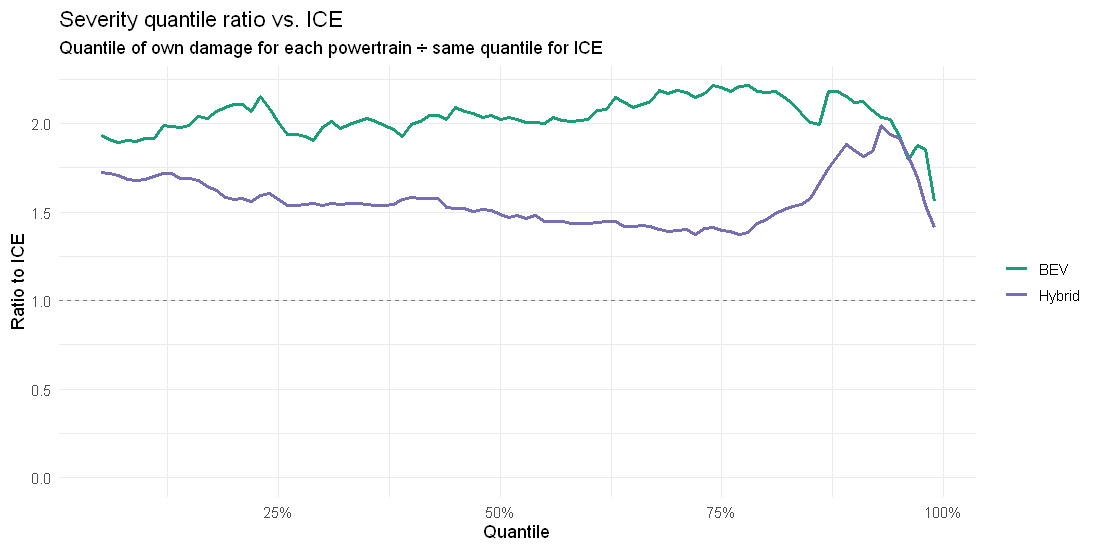

In [15]:
probs <- seq(0.05, 0.99, by = 0.01)

quantile_ratio <- map(c("BEV", "Hybrid"), \(pt) {
  tibble(prob     = probs,
         ratio    = quantile(sev$own_damage[sev$Powertrain == pt],  probs) /
                    quantile(sev$own_damage[sev$Powertrain == "ICE"], probs),
         Powertrain = pt)
}) |> list_rbind()

ggplot(quantile_ratio, aes(prob, ratio, colour = Powertrain)) +
  geom_hline(yintercept = 1, linetype = "dashed", colour = "grey50") +
  geom_line(linewidth = 1) +
  scale_colour_manual(values = pt_colours) +
  scale_x_continuous(labels = percent) +
  scale_y_continuous(limits = c(0, NA)) +
  labs(title = "Severity quantile ratio vs. ICE",
       subtitle = "Quantile of own damage for each powertrain ÷ same quantile for ICE",
       x = "Quantile", y = "Ratio to ICE", colour = NULL)

### 3.2 Severity relative to vehicle value
BEVs are worth about 2.3× ICE vehicles (notebook 01). The **damage ratio** (own damage ÷ vehicle value) shows how much of the severity gap remains once the sum insured is taken into account.

In [16]:
severity_summary(filter(sev, !is.na(damage_ratio)), damage_ratio) |>
  select(Powertrain, claims, mean, median, p75, p95) |>
  mutate(across(mean:p95, ~ percent(.x, accuracy = 0.1)))

Powertrain,claims,mean,median,p75,p95
<fct>,<int>,<chr>,<chr>,<chr>,<chr>
BEV,650,17.9%,7.4%,18.1%,90.7%
Hybrid,1208,19.2%,8.0%,17.5%,92.2%
ICE,3602,20.0%,9.3%,21.3%,91.1%


In [17]:
# Side check: third-party property damage (Collision with TP claims only)
sev_tp <- claims_ip |> filter(!cat_event, claim_type == "Collision with TP", tp_damage > 0)

severity_summary(sev_tp, tp_damage) |>
  select(Powertrain, claims, mean, median, p95) |>
  mutate(across(mean:p95, ~ comma(.x, accuracy = 1, prefix = "₪")))

Powertrain,claims,mean,median,p95
<fct>,<int>,<chr>,<chr>,<chr>
BEV,254,"₪12,576","₪8,497","₪40,251"
Hybrid,433,"₪11,885","₪7,655","₪36,229"
ICE,1391,"₪13,400","₪8,574","₪39,247"


## 4. Total Loss / Write-off Analysis
### 4.1 Total-loss rate by powertrain
Theft write-offs are unrelated to repair economics, so the rate is shown both **with and without theft**. The ex-theft rate is the relevant test of the battery-replacement-threshold hypothesis.

In [18]:
tl_base <- claims_ip |> filter(!cat_event)

tl_rates <- bind_rows(
  `All claims`        = tl_base,
  `Excluding theft`   = filter(tl_base, claim_type != "Theft"),
  .id = "basis"
) |>
  group_by(basis, Powertrain) |>
  summarise(claims = n(), total_losses = sum(total_loss)) |>
  mutate(rate    = total_losses / claims,
         ci_low  = rate - 1.96 * sqrt(rate * (1 - rate) / claims),
         ci_high = rate + 1.96 * sqrt(rate * (1 - rate) / claims)) |>
  ungroup()

tl_rates |> mutate(across(rate:ci_high, ~ percent(.x, accuracy = 0.1)))

basis,Powertrain,claims,total_losses,rate,ci_low,ci_high
<chr>,<fct>,<int>,<int>,<chr>,<chr>,<chr>
All claims,BEV,696,65,9.3%,7.2%,11.5%
All claims,Hybrid,1287,136,10.6%,8.9%,12.2%
All claims,ICE,3907,403,10.3%,9.4%,11.3%
Excluding theft,BEV,691,62,9.0%,6.8%,11.1%
Excluding theft,Hybrid,1202,66,5.5%,4.2%,6.8%
Excluding theft,ICE,3771,298,7.9%,7.0%,8.8%


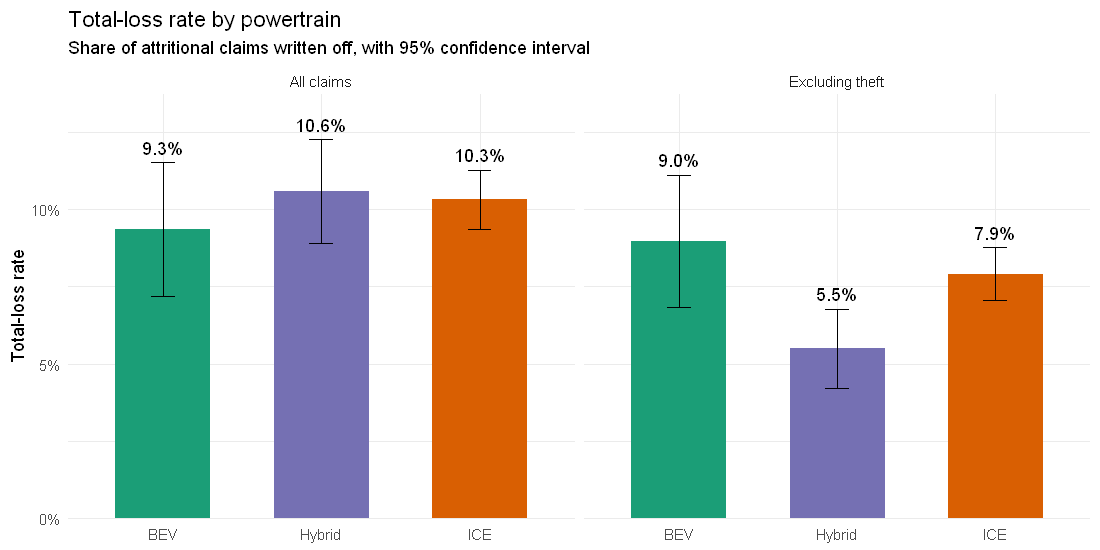

In [19]:
ggplot(tl_rates, aes(Powertrain, rate, fill = Powertrain)) +
  geom_col(width = 0.6) +
  geom_errorbar(aes(ymin = ci_low, ymax = ci_high), width = 0.15) +
  geom_text(aes(y = ci_high, label = percent(rate, accuracy = 0.1)), vjust = -0.6) +
  facet_wrap(~ basis) +
  scale_fill_manual(values = pt_colours, guide = "none") +
  scale_y_continuous(labels = percent, expand = expansion(mult = c(0, 0.12))) +
  labs(title = "Total-loss rate by powertrain",
       subtitle = "Share of attritional claims written off, with 95% confidence interval",
       x = NULL, y = "Total-loss rate")

### 4.2 Partial vs. total loss cost

In [20]:
sev |>
  mutate(loss_type = if_else(total_loss, "Total loss", "Partial loss")) |>
  group_by(Powertrain, loss_type) |>
  summarise(claims             = n(),
            median_cost        = median(own_damage),
            mean_cost          = mean(own_damage),
            median_damage_ratio = median(damage_ratio, na.rm = TRUE),
            total_cost         = sum(own_damage)) |>
  mutate(share_of_cost = percent(total_cost / sum(total_cost), accuracy = 0.1)) |>
  ungroup() |>
  mutate(across(c(median_cost, mean_cost), ~ comma(.x, accuracy = 1, prefix = "₪")),
         median_damage_ratio = percent(median_damage_ratio, accuracy = 1)) |>
  select(-total_cost)

Powertrain,loss_type,claims,median_cost,mean_cost,median_damage_ratio,share_of_cost
<fct>,<chr>,<int>,<chr>,<chr>,<chr>,<chr>
BEV,Partial loss,587,"₪8,445","₪14,200",6%,58.5%
BEV,Total loss,63,"₪87,631","₪93,980",91%,41.5%
Hybrid,Partial loss,1074,"₪6,025","₪9,510",7%,47.1%
Hybrid,Total loss,135,"₪83,437","₪84,901",91%,52.9%
ICE,Partial loss,3262,"₪3,995","₪6,717",8%,54.2%
ICE,Total loss,394,"₪39,553","₪46,998",91%,45.8%


## 5. Data Quality Audit
Every issue found in the claims extract and the join. Each one is an action item for the ETL script.

In [21]:
dq <- distinct(claims_raw)

tribble(
  ~issue,                                                ~records,
  "Exact duplicate claim rows",                           nrow(claims_raw) - nrow(dq),
  "Amounts stored as text (₪ / thousands separator)",     sum(str_detect(dq$Own_Damage_Amount, "[^0-9.-]")) +
                                                          sum(str_detect(dq$TP_Damage_Amount, "[^0-9.-]"), na.rm = TRUE),
  "Own_Damage_Amount negative",                           sum(parse_number(dq$Own_Damage_Amount) < 0),
  "Own_Damage_Amount zero",                               sum(parse_number(dq$Own_Damage_Amount) == 0),
  "Claim_Type missing",                                   sum(is.na(dq$Claim_Type)),
  "Claim_Type label variants (14 labels → 8 types)",      sum(!dq$Claim_Type %in% c("Collision_No_TP", "Collision_With_TP", "Single_Vehicle_Accident",
                                                                                  "Natural_Hazard", "Malicious_Damage", "Theft", "Fire", "Flood") &
                                                              !is.na(dq$Claim_Type)),
  "Orphan claims (Policy_ID not in policies)",            n_orphans,
  "Accident before policy start",                         sum(claims$accident_date < claims$start_date, na.rm = TRUE),
  "Accident after policy end",                            sum(claims$accident_date > claims$end_date, na.rm = TRUE),
  "Policy has no valid exposure",                         sum(is.na(claims$exposure)),
  "Own damage > 2 × vehicle value (likely entry error)",  sum(claims$damage_ratio > 2, na.rm = TRUE),
  "CAT event claims (2025-01-19)",                        sum(claims$cat_event)
)

issue,records
<chr>,<int>
Exact duplicate claim rows,60
Amounts stored as text (₪ / thousands separator),340
Own_Damage_Amount negative,35
Own_Damage_Amount zero,350
Claim_Type missing,120
Claim_Type label variants (14 labels → 8 types),362
Orphan claims (Policy_ID not in policies),72
Accident before policy start,12
Accident after policy end,82


## 6. Key Findings & Implications for the GLM Stage

**1. Frequency barely differs by powertrain.** Excluding the CAT event, BEVs make **16.9%** claims per vehicle-year (95% CI 15.6–18.1%), against **16.0%** for ICE (15.5–16.5%) and 16.6% for Hybrid. The confidence intervals overlap, and the claims-per-policy profile is almost identical (≈ 85% with no claim, 13% with one, 2% with two or more).

**2. A single-day catastrophe distorts the raw data.** 556 claims fall on **2025-01-19**, 95% of them natural-hazard claims. That one event pushes January 2025 frequency to ~34% annualised, against a steady ~16% in other months. Outside this event there is no trend or seasonality.

**3. BEV severity is about 2× ICE, a uniform shift rather than a heavy tail.** Median own damage is ₪9.6k for BEV vs. ₪4.7k for ICE, and the mean is ₪21.9k vs. ₪11.1k. The BEV ÷ ICE quantile ratio stays at about 2.0 from the 5th to the 95th percentile, and the mean-to-median ratio is the same (2.3). However, relative to vehicle value BEVs are *not* more expensive to repair: the median damage ratio is 7.4% for BEV vs. 9.3% for ICE. The raw severity gap therefore looks largely explained by the higher sum insured (notebook 01). Third-party damage is similar across powertrains (median ≈ ₪8.5k), as expected.

**4. No clear battery-driven write-off effect.** Excluding theft, the BEV total-loss rate is **9.0%** (6.8–11.1%) against **7.9%** for ICE (7.0–8.8%). The difference is not statistically clear, because there are only 63 BEV total losses. All powertrains are written off at the same point, a median damage ratio of 91% of value. Theft drives the all-claims rate for Hybrids (6.6% of their claims) and ICE (3.5%), but rarely affects BEVs (0.7%). Total losses account for 42–53% of own-damage cost in every group.

**Guidelines for the GLM stage (notebook 04)**

| Component | Model | Base & key terms |
|---|---|---|
| Frequency | Poisson GLM, log link, `offset(log(exposure))`. Switch to Negative Binomial if the dispersion test rejects Poisson | Policy-level counts, attritional claims (CAT event excluded) |
| Severity | Gamma GLM, log link | Positive, valid own-damage amounts. **Include `log(Vehicle_Value)`**: the key test is whether the BEV effect survives it |
| Total loss | Logistic (binomial) GLM | Claim level. Claim type as a covariate, or theft excluded |
| All models | Powertrain (ICE = reference), vehicle age, value tier, driver factors | Price the CAT event as a separate loading, not through attritional frequency |

**ETL action items for `src/01_etl_merge_and_clean.R`** (see the audit table in §5)
- Remove the 60 exact duplicate rows. Parse text amounts (₪ and thousands separators).
- Investigate the 35 negative and 350 zero own-damage amounts (possible recoveries, or claims with third-party damage only), and the 12 claims with own damage > 2 × vehicle value (likely entry errors).
- Map the 14 claim-type labels to 8 types. Assign "Unspecified" to the 120 missing and 86 "Accident" labels.
- Drop the 72 orphan claims and the 94 accidents outside the policy period. Flag the CAT event as `cat_event`.